## Quantum circuit model
https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit

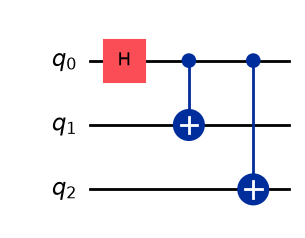

In [1]:
from qiskit import QuantumCircuit

# Create a circuit with a register of three qubits
circ = QuantumCircuit(3)
# H gate on qubit 0, putting this qubit in a superposition of |0> + |1>.
circ.h(0)
# A CX (CNOT) gate on control qubit 0 and target qubit 1 generating a Bell state.
circ.cx(0, 1)
# CX (CNOT) gate on control qubit 0 and target qubit 2 resulting in a GHZ state.
circ.cx(0, 2)
# Draw the circuit
circ.draw('mpl')

In [3]:
# Barrier

from qiskit.circuit import QuantumCircuit

qc = QuantumCircuit(1)
qc.x(0)
qc.barrier()
qc.x(0)
qc.draw()

┌───┐ ░ ┌───┐
q: ┤ X ├─░─┤ X ├
   └───┘ ░ └───┘

In [7]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr

n = 3

qr = QuantumRegister(n, 'q')
cr = ClassicalRegister(n, 'c')
creg = ClassicalRegister(1, 'parity')

qc = QuantumCircuit(qr, cr, creg)

# Measure qubits into classical bits
qc.measure(qr, cr)

# Calculate parity
parity = expr.lift(cr[0])

for i in range(1, n):
    parity = expr.bit_xor(cr[i], parity)

qc.store(creg[0], parity)

In [ ]:
# get_control_flow_name_mapping

from qiskit.circuit import get_control_flow_name_mapping

ctrl_flow_name_map = get_control_flow_name_mapping()
if_else_object = ctrl_flow_name_map["if_else"]

print(if_else_object)

<class 'qiskit.circuit.controlflow.if_else.IfElseOp'>


In [10]:
# cf_instruction: CircuitInstruction = ...
# cf_operation: ControlFlowOp = cf_instruction.operation
# for block in blocks:
#     # Mappings of "inner" qubits/clbits to the outer ones.
#     qubit_map = dict(zip(block.qubits, cf_instruction.qubits))
#     clbit_map = dict(zip(block.clbits, cf_instruction.clbits))

#     # ... do something with `block` ...

In [11]:
# Delayed-resolution scheduling

from qiskit import QuantumCircuit
from qiskit.circuit.classical import expr

qc = QuantumCircuit(3, 3)
# This sets up three duration "degrees of freedom" that will
# be resolved later by a backend compiler.
a = qc.add_stretch("a")
b = qc.add_stretch("b")
c = qc.add_stretch("c")

# This set of operations involves feed-forward operations that
# Qiskit cannot know the length of.
with qc.box():
    qc.h(1)
    qc.cx(1, 2)
    qc.measure([1, 2], [1, 2])
    with qc.if_test(expr.equal(qc.clbits[1], qc.clbits[2])):
        qc.h(1)

# While that stuff is happening to qubits (1, 2), we want
# qubit 0 to do two different DD sequences.  The two DD
# sequences are fixed to be the same length as each other,
# even though they're both internally stretchy.
with qc.box(duration=a):
    # Textbook NMRish XX DD.
    qc.delay(b, 0)
    qc.x(0)
    qc.delay(expr.mul(2, b), 0)
    qc.x(0)
    qc.delay(b, 0)
with qc.box(duration=a):
    # XY4-like DD.
    for _ in range(2):
        qc.delay(c, 0)
        qc.y(0)
        qc.delay(expr.mul(2, c), 0)
        qc.x(0)
        qc.delay(c, 0)

In [12]:
# Creating instruction subclasses

import math
import numpy as np
from qiskit.circuit import Gate, QuantumCircuit

class RXZGate(Gate):
    def __init__(self, theta):
        # Initialize with our name, number of qubits and parameters.
        super().__init__("rxz", 2, [theta])

    def _define(self):
        # Our base definition is an RZXGate, applied "backwards".
        defn = QuantumCircuit(2)
        defn.rzx(1, 0)
        self._definition = defn

    def inverse(self, annotated = False):
        # We have an efficient representation of our inverse,
        # so we'll override this method.
        return RXZGate(-self.params[0])

    def power(self, exponent: float):
        # Also we have an efficient representation of power.
        return RXZGate(exponent * self.params[0])

    def __array__(self, dtype=None, copy=None):
        if copy is False:
            raise ValueError("unable to avoid copy while creating an array as requested")
        cos = math.cos(0.5 * self.params[0])
        isin = 1j * math.sin(0.5 * self.params[0])
        return np.array([
            [cos, -isin, 0, 0],
            [-isin, cos, 0, 0],
            [0, 0, cos, isin],
            [0, 0, isin, cos],
        ], dtype=dtype)

In [14]:
from qiskit.circuit import SessionEquivalenceLibrary, Parameter
from qiskit.circuit.library import RZXGate
from qiskit import QuantumCircuit

theta = Parameter("theta")

equiv = QuantumCircuit(2)
equiv.h(0)
equiv.cx(1, 0)
equiv.rz(theta, 0)
equiv.cx(1, 0)
equiv.h(0)

SessionEquivalenceLibrary.add_equivalence(RZXGate(theta), equiv)

In [15]:
# Bit labelling

from qiskit import QuantumCircuit

qc = QuantumCircuit(5, 5)
qc.x(0)
qc.x(1)
qc.x(4)
qc.measure(range(5), range(5))

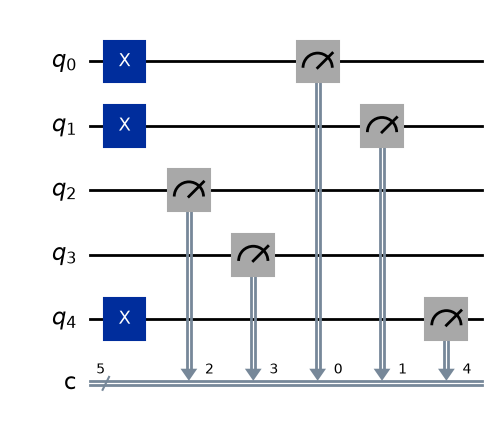

In [16]:
qc.draw("mpl")

In [17]:
# Matrix representations

import numpy
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

state_0 = [1, 0]  # defined representation of |0>
state_1 = [0, 1]  # defined representation of |1>

# Circuit that creates basis state |10011>, where
# binary 10011 has the decimal value 19.
qc = QuantumCircuit(5)
qc.x(0)
qc.x(1)
qc.x(4)
qiskit_sv = Statevector(qc)

# List index 'n' corresponds to qubit 'n'.
individual_states = [
    state_1,
    state_1,
    state_0,
    state_0,
    state_1,
]
# Start from a scalar.
manual_sv = [1]
for qubit_state in individual_states:
    # Each new qubit goes "on the left".
    manual_sv = numpy.kron(qubit_state, manual_sv)

# Now `qiskit_sv` and `manual_sv` are the same, and:
assert manual_sv[19] == 1
assert qiskit_sv[19] == 1

In [18]:
import numpy
from qiskit.circuit.library import CXGate

numpy.array(CXGate())

array([[1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j],
       [0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j]])

In [19]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator

# Build the natural representation of `CCX` with the
# control qubits being `[0, 1]`, relative to the
# bitstring state "01", such that qubit 0 must be in |1>
# and qubit 1 must be in |0>.  The target qubit is 2.
ccx_natural = QuantumCircuit(3)
ccx_natural.ccx(0, 1, 2, ctrl_state=1)

# Build the same circuit in terms of the all-ones CCX.
# Note that we flip _qubit 1_, because that's the one
# that differs from the all-ones state.
ccx_relative = QuantumCircuit(3)
ccx_relative.x(1)
ccx_relative.ccx(0, 1, 2)
ccx_relative.x(1)

assert Operator(ccx_relative) == Operator(ccx_natural)